# Gemfinder pipeline walkthrough

Gemfinder compares how two groups of students answered a survey question, say one class against the whole country. To decide whether the difference matters, it needs to know how big a difference could appear just by chance. RYA's neural network (EXP002) estimates that, and it works well most of the time. It goes quietly wrong when one group is tiny next to the other, which is one of the most common real questions.

The pipeline keeps RYA's method exactly as it is and adds checks around it: catch the cases the network can't handle, send them to a slower but reliable simulation, and report how sure we are of the answer.

**To run it:** open this notebook from the repo folder with the **Python (scrp)** kernel, then Restart and Run All. It takes about a minute. The pipeline needs `scipy` and `scikit-learn` on top of the baseline environment (`pip install scipy scikit-learn`).

Everything here uses made-up test cases plus one case from RYA's training data. No real student survey responses are used.

## 1. Load the pipeline

This loads RYA's network and SIN-WEI's screening model. `ROOT` is the data folder, found the same way as in the baseline walkthrough.

`EPSILON` is the smallest difference we treat as meaningful. 0.1 is a placeholder until RYA tells us the value they use.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from scrp_toolkit.config import default_project_root, resolve_project_paths
from scrp_toolkit.pipeline.run import build_pipeline
from scrp_toolkit.pipeline.scenarios import build_scenarios

pd.set_option("display.max_colwidth", 80, "display.width", 200)
ROOT = default_project_root()
EPSILON = 0.1

pipeline = build_pipeline(ROOT)
print("Data folder:", os.path.relpath(ROOT))
print(pipeline.net.predictor.describe())

Data folder: data
Model: 20 layers, width 256, 40 features, P_transform='all_P_asymm'


## 2. The test cases

Each case is two groups' answers to one question (how many picked options 1, 2, 3 and 4), plus that question's unreliability matrix ρ. ρ describes how often a student gives a different answer from their "real" one when asked again.

Each case is built to show one part of the pipeline. The last column says what should happen.

In [2]:
cases = build_scenarios(pipeline.net.predictor.p_matrices, resolve_project_paths(ROOT).instance_dir, EPSILON)

pd.DataFrame({
    "case": [c.name for c in cases],
    "group X answers": [list(c.request.x.astype(int)) for c in cases],
    "group Y answers": [list(c.request.y.astype(int)) for c in cases],
    "shows": [c.objective for c in cases],
    "what should happen": [c.expect for c in cases],
})

,case,group X answers,group Y answers,shows,what should happen
0,A. Typical comparison,"[40, 52, 7, 14]","[9, 17, 54, 12]",O4 network + O3 range,"passes screening, uses the network, GREEN"
1,B. Classroom (n=8) vs national,"[2, 1, 2, 3]","[1800, 2880, 2520, 1800]",O1 screening + O2 fallback,"flagged, uses the fallback; the network alone would wrongly call a meaningfu..."
2,C. Classroom (n=25) vs national,"[3, 6, 10, 6]","[1800, 2880, 2520, 1800]",O1 screening,the classifier passes it; the small-group rule sends it to the fallback
3,D. Everyone gave one answer,"[0, 0, 12, 0]","[30, 41, 25, 14]",O1 degeneracy safeguard,"flagged, uses the fallback"
4,E. Corrupt rho (row sums 1.06),"[40, 52, 7, 14]","[9, 17, 54, 12]",O1 rho check,"rejected, RED, no p-value"
5,F. Six-option item,"[3, 4, 5, 6]","[6, 5, 4, 3]",O1 scope check,"rejected, RED"
6,"G. Cohort above training range (n=15,000)","[2700, 4950, 4350, 3000]","[1800, 2880, 2520, 1800]",O1 training-range check,"flagged, uses the fallback"
7,"H. Rho from a small retest study (15/row, SYNTHETIC)","[24, 33, 24, 19]","[14, 30, 34, 22]",O3 rho uncertainty,"wide p-range that crosses 0.05, AMBER"
8,"I. Same, large retest study (2,000/row, SYNTHETIC)","[24, 33, 24, 19]","[14, 30, 34, 22]",O3 rho uncertainty,"narrow p-range, GREEN"
9,"J. RYA training instance n=6 vs 5,215 (ry24)","[3, 1, 1, 1]","[979, 1468, 900, 1868]",O1 acceptance case (SIN-WEI),"flagged by the classifier, uses the fallback"


## 3. Following one case through the pipeline

Case B is a class of 8 students compared with a national group of 9,000, on question `ry9`. This is exactly the kind of comparison the project set out to fix.

In [3]:
case = next(c.request for c in cases if c.name.startswith("B."))
print("class   :", case.x.astype(int), " (", int(case.x.sum()), "students )")
print("national:", case.y.astype(int), " (", int(case.y.sum()), "students )")
print("\nrho for ry9 (row = a student's real answer, column = the answer they gave):")
pd.DataFrame(case.P, index=[f"real {i}" for i in range(1, 5)], columns=[f"gave {i}" for i in range(1, 5)]).round(2)

class   : [2 1 2 3]  ( 8 students )
national: [1800 2880 2520 1800]  ( 9000 students )

rho for ry9 (row = a student's real answer, column = the answer they gave):


,gave 1,gave 2,gave 3,gave 4
real 1,0.43,0.41,0.10,0.06
real 2,0.05,0.57,0.28,0.10
real 3,0.01,0.12,0.61,0.27
real 4,0.01,0.02,0.16,0.81


### Step 1. Is ρ usable? *(Objective 1, SIN-WEI)*

Before anything else, ρ is checked: it must be 4×4, have no negative numbers, and each row must add up to 1 (small rounding is fine). Six-option questions are turned away because the network was never trained on them. If ρ fails, the pipeline stops here and returns RED with no answer.

Here ρ passes with a note: its rows are rounded to two decimals, so they add up to 0.99 or 1.01.

In [4]:
from scrp_toolkit.pipeline.screen import validate_rho
rho_check = validate_rho(case)
print(rho_check.status, "-", "; ".join(rho_check.reasons) or "no notes")

warn - rho row sums rounded (max error 0.010); kept as given


### Step 2. Where to test: the boundary pair *(RYA's method)*

The question being tested is "are these groups at least ε apart?". So the pipeline asks: if the true gap were exactly ε, how unusual would the gap we saw be?

To set that up, both groups' answer shares are slid toward each other, keeping the group sizes, until the gap is exactly ε. That adjusted pair is called the boundary pair, and everything after this works on it.

*This follows RYA's draft paper. We haven't seen the code their portal actually uses, so this step may change.*

In [5]:
from scrp_toolkit.pipeline.boundary import find_boundary
boundary = find_boundary(case)
print(f"gap we saw: {boundary.d_norm_observed:.3f}    gap at the boundary: {boundary.d_norm_boundary:.3f} (= epsilon)")

pd.DataFrame({"class (seen)": case.x, "class (boundary)": boundary.x.round(2),
              "national (seen)": case.y, "national (boundary)": boundary.y.round(0)},
             index=[f"answer {i}" for i in range(1, 5)])

gap we saw: 0.221    gap at the boundary: 0.100 (= epsilon)


,class (seen),class (boundary),national (seen),national (boundary)
answer 1,2.0,1.94,1800.0,1872.0
answer 2,1.0,1.25,2880.0,2600.0
answer 3,2.0,2.04,2520.0,2477.0
answer 4,3.0,2.78,1800.0,2051.0


### Step 3. Can the network be trusted here? *(Objective 1, SIN-WEI)*

SIN-WEI's screening model estimates the chance that the network's answer will be wrong for this kind of input. It looks at the pair we saw and at the boundary pair. Anything above 0.10 is flagged.

Two simple rules are added on top:
- group sizes outside what the network was trained on (5 to 9,940);
- a group smaller than 30 compared with one at least 20 times bigger.

A flagged case goes to the fallback instead of the network. Case B trips three of these checks.

In [6]:
from scrp_toolkit.pipeline.screen import screen
screening = screen(case, rho_check, boundary, pipeline.gate)
print("decision:", screening.route)
for reason in screening.reasons:
    print(" -", reason)

decision: FLAGGED
 - classifier flags observed pair (p=1.00)
 - classifier flags boundary pair (p=1.00)
 - small group (8) against a group 1125x larger


### Step 4. How much would the gap vary by chance? *(Objectives 4 and 2)*

There are two ways to answer this:

- **The network** *(Murat's faster, smaller version of EXP002)* predicts a smooth curve, a Gamma distribution, in a few milliseconds.
- **The fallback** *(Shuyun's method)* runs RYA's own simulation 4,000 times (each student answers through ρ, the gap is measured, repeat) and reads the answer straight off the results.

The pipeline only runs the fallback for flagged cases. Here we run both, so you can see why it's needed.

95% of chance gaps fall below:  network 0.204   simulation 0.674


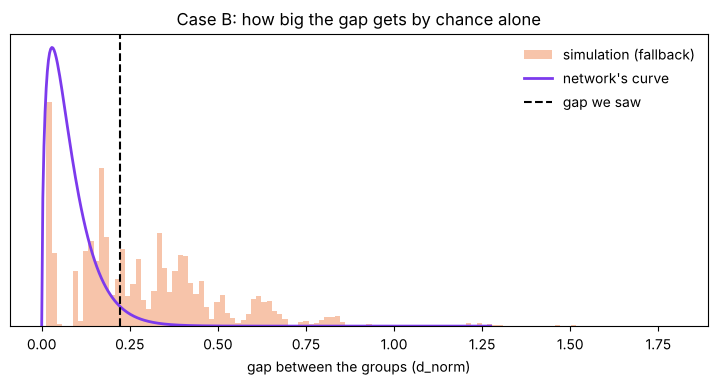

In [7]:
from scrp_toolkit.pipeline.nulls import simulated_null
network = pipeline.net(case, boundary)
simulation = simulated_null(case, boundary)

print(f"95% of chance gaps fall below:  network {network.q95:.3f}   simulation {simulation.q95:.3f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(simulation.draws, bins=120, density=True, color="#EA580C", alpha=0.35, label="simulation (fallback)")
xs = np.linspace(0, np.quantile(simulation.draws, 0.995), 400)
ax.plot(xs, stats.gamma.pdf(xs, network.params["shape"], scale=1 / network.params["rate"]),
        color="#7C3AED", lw=2, label="network's curve")
ax.axvline(boundary.d_norm_observed, color="black", ls="--", label="gap we saw")
ax.set_xlabel("gap between the groups (d_norm)"); ax.set_yticks([])
ax.set_title("Case B: how big the gap gets by chance alone")
ax.legend(frameon=False); plt.show()

With only 8 students, the class can only produce a few different answer patterns, so the simulated gaps bunch into separate lumps. A single smooth curve can't follow that shape. The network's curve sits far too low and too narrow, so it makes the gap we saw look rarer than it really is.

### Step 5. The test

The p-value is the chance of a gap at least as big as the one we saw, if the true gap were only ε. Below 0.05 means "meaningful difference".

In [8]:
from scrp_toolkit.pipeline.boundary import minimal_effects_test
for name, null in [("network only (original)", network), ("simulation (pipeline)", simulation)]:
    test = minimal_effects_test(case, boundary, null)
    print(f"{name:26s} p = {test.p_value:.3f}   ->  {test.decision}")

network only (original)    p = 0.037   ->  meaningful difference
simulation (pipeline)      p = 0.561   ->  no meaningful difference shown


Using the network alone, the original set-up would report a meaningful difference for this class. The simulation says the gap is well within what chance produces. Because screening flagged the case, the pipeline gives the simulation's answer.

### Step 6. How sure are we about ρ? *(Objective 3, Pratik)*

ρ comes from a test-retest study, so it is an estimate, but the original method treats it as exact. The pipeline re-runs the whole test with a few slightly different versions of ρ (Pratik's method) and reports the range of p-values. If the decision would change somewhere in that range, the result is marked AMBER.

In [9]:
result = pipeline.run(case)
spread = result.uncertainty
print(f"p-value {result.p_value:.3f}, ranging from {spread.p_low:.3f} to {spread.p_high:.3f} ({spread.source})")
print("same decision across the range:", spread.decision_stable)

p-value 0.561, ranging from 0.524 to 0.581 (rho error mass +/-5%)
same decision across the range: True


### What the user sees

The decision, the p-value with its range, and a colour:

- **GREEN**: screening passed and the decision is stable.
- **AMBER**: the fallback was used, or the decision could flip.
- **RED**: the input was rejected, so there is no answer.

Case B is AMBER because it needed the fallback.

In [10]:
pd.Series(result.summary())[["n_X", "n_Y", "route", "p_value", "p_range", "decision", "flag", "flag_reasons"]]

n_X                                                                                           8
n_Y                                                                                        9000
route                                                                                   FLAGGED
p_value                                                                                  0.5609
p_range                                                                        (0.5243, 0.5809)
decision                                                         no meaningful difference shown
flag                                                                                      AMBER
flag_reasons    classifier flags observed pair (p=1.00); classifier flags boundary pair (p=1...
dtype: object

## 4. All the test cases

Each case is run three ways:
- **original**: straight to the network, with no checks;
- **pipeline**;
- **truth**: RYA's simulation with 20,000 runs.

The truth and the fallback use the same simulation, so this shows how far the network is from RYA's own model, not whether that model is right.

In [11]:
from scrp_toolkit.pipeline.demo import run_demo, readable
demo = run_demo(ROOT, EPSILON)
readable(demo).rename(columns={"p_direct": "p original", "p_robust": "p pipeline", "p_truth": "p truth"})

,scenario,n_X,n_Y,route,null,p original,p pipeline,p truth,p_range,flag
0,A. Typical comparison,113,92,PASS,nn_fp32,0.000,0.000,0.000,0.000-0.000,GREEN
1,B. Classroom (n=8) vs national,8,9000,FLAGGED,mc_empirical,0.037,0.561,0.551,0.524-0.581,AMBER
2,C. Classroom (n=25) vs national,25,9000,FLAGGED,mc_empirical,0.137,0.334,0.338,0.327-0.347,AMBER
3,D. Everyone gave one answer,12,110,FLAGGED,mc_empirical,0.000,0.000,0.000,0.000-0.001,AMBER
4,E. Corrupt rho (row sums 1.06),113,92,REJECT,NaN,0.000,-,-,-,RED
5,F. Six-option item,18,18,REJECT,NaN,1.000,-,-,-,RED
6,"G. Cohort above training range (n=15,000)",15000,9000,FLAGGED,mc_empirical,1.000,1.000,1.000,1.000-1.000,AMBER
7,"H. Rho from a small retest study (15/row, SYNTHETIC)",100,100,PASS,nn_fp32,0.216,0.216,0.218,0.016-0.525,AMBER
8,"I. Same, large retest study (2,000/row, SYNTHETIC)",100,100,PASS,nn_fp32,0.216,0.216,0.218,0.187-0.226,GREEN
9,"J. RYA training instance n=6 vs 5,215 (ry24)",6,5215,FLAGGED,mc_empirical,0.087,0.360,0.353,0.334-0.376,AMBER


**What to notice**

- **A**: an ordinary comparison. The network is fine and the result is GREEN.
- **B, C, J**: small classes against big groups.
  - The original p-values are far too small. In B it wrongly calls a meaningful difference.
  - The pipeline sends all three to the simulation and lands on the truth.
  - SIN-WEI's model lets C through; the small-group rule catches it.
- **D, G**: one group all gave the same answer, or a group is bigger than anything the network was trained on. Both are flagged.
- **E, F**: a broken ρ and a six-option question. The original still produces a number; the pipeline refuses (RED).
- **H vs I**: the same comparison with ρ from a small (15 per row) or large (2,000 per row) retest study. The p-value is the same, but with the small study the range crosses 0.05, so H is AMBER and I is GREEN.

Why each case got its colour:

In [12]:
demo[["scenario", "flag", "why"]]

,scenario,flag,why
0,A. Typical comparison,GREEN,rho row sums rounded (max error 0.010); kept as given
1,B. Classroom (n=8) vs national,AMBER,classifier flags observed pair (p=1.00); classifier flags boundary pair (p=1...
2,C. Classroom (n=25) vs national,AMBER,small group (25) against a group 360x larger; fallback null (mc_empirical); ...
3,D. Everyone gave one answer,AMBER,observed group answers all in one category; classifier flags observed pair (...
4,E. Corrupt rho (row sums 1.06),RED,rho row sums off by up to 0.060 (limit 0.02)
5,F. Six-option item,RED,six-option chs item: no model exists for it
6,"G. Cohort above training range (n=15,000)",AMBER,group sizes 15000/9000 outside training range 5-9940; fallback null (mc_empi...
7,"H. Rho from a small retest study (15/row, SYNTHETIC)",AMBER,decision flips within rho uncertainty (p 0.016-0.525); rho row sums rounded ...
8,"I. Same, large retest study (2,000/row, SYNTHETIC)",GREEN,rho row sums rounded (max error 0.010); kept as given
9,"J. RYA training instance n=6 vs 5,215 (ry24)",AMBER,classifier flags observed pair (p=1.00); classifier flags boundary pair (p=1...


## 5. Over 400 random comparisons

The same three-way comparison on 400 random comparisons, grouped by how much bigger one group is than the other. It takes about 20 seconds.

In [13]:
from scrp_toolkit.pipeline.benchmark import run_benchmark, summarise
summarise(run_benchmark(ROOT, n_cases=400)).T

,1-2x,2-10x,10-100x,100-2000x,all
cases,100.000,100.000,100.000,100.000,400.000
flagged_%,0.000,0.000,5.000,88.000,23.250
direct_no_answer,0.000,0.000,0.000,0.000,0.000
direct_agree_%,98.000,96.000,97.000,89.000,95.000
direct_false_pos,0.000,0.000,0.000,8.000,8.000
direct_median_abs_p_err,0.000,0.000,0.009,0.111,0.006
direct_median_ms,4.178,4.105,4.106,4.078,4.112
robust_no_answer,0.000,0.000,0.000,0.000,0.000
robust_agree_%,98.000,96.000,97.000,98.000,97.250
robust_false_pos,0.000,0.000,0.000,0.000,0.000


**Groups of similar size, up to 100× apart:** both versions agree with the truth 96 to 98% of the time. Screening lets almost everything through, so both are using the network.

**One group 100× bigger or more:**

| | Agrees with the truth | False alarms |
| --- | --- | --- |
| Original | 89% | 8 |
| Pipeline | 98% | 0 |

The extra checking makes these comparisons a few times slower, but each one still takes only milliseconds.

## 6. A Bayesian second opinion *(Objective 3, Pratik; not part of the pipeline)*

Pratik's Bayesian version asks the question differently: given the answers we saw, how likely is it that the real gap is bigger than ε? We call it meaningful when that chance is at least 95%. It is shown here only for comparison.

In [14]:
from scrp_toolkit.pipeline.bayes_eval import compare_demo
bayes = compare_demo(ROOT, EPSILON)
fmt = lambda v: "-" if not isinstance(v, (int, float)) or not np.isfinite(v) else f"{v:.3f}"
pd.DataFrame({
    "case": bayes["scenario"],
    "pipeline p": bayes["pipeline_p"].map(fmt),
    "pipeline says": bayes["pipeline_decision"],
    "chance gap > epsilon": bayes["bayes_P_d_gt_eps"].map(fmt),
    "Bayesian says": bayes["bayes_decision"],
    "agree": bayes["agree"],
})

,case,pipeline p,pipeline says,chance gap > epsilon,Bayesian says,agree
0,A. Typical comparison,0.000,meaningful difference,1.000,meaningful difference,True
1,B. Classroom (n=8) vs national,0.561,no meaningful difference shown,0.899,no meaningful difference shown,True
2,C. Classroom (n=25) vs national,0.334,no meaningful difference shown,0.733,no meaningful difference shown,True
3,D. Everyone gave one answer,0.000,meaningful difference,1.000,meaningful difference,True
4,E. Corrupt rho (row sums 1.06),-,NaN,-,NaN,None
5,F. Six-option item,-,NaN,-,NaN,None
6,"G. Cohort above training range (n=15,000)",1.000,no meaningful difference shown,0.000,no meaningful difference shown,True
7,"H. Rho from a small retest study (15/row, SYNTHETIC)",0.216,no meaningful difference shown,0.699,no meaningful difference shown,True
8,"I. Same, large retest study (2,000/row, SYNTHETIC)",0.216,no meaningful difference shown,0.627,no meaningful difference shown,True
9,"J. RYA training instance n=6 vs 5,215 (ry24)",0.360,no meaningful difference shown,0.941,no meaningful difference shown,True


They agree on every case that gets tested. One thing to watch: for small groups the Bayesian ranges are too narrow (they contain the true value about half the time instead of 95%). That has gone back to Pratik.

## Settings you can change

Pass any of these to `build_pipeline`, for example `build_pipeline(ROOT, weights="fp16")`.

| Setting | Default | What it does |
| --- | --- | --- |
| `weights` | `"fp32"` | `"fp16"` uses the half-size network meant for the browser. It gives the same decisions here. |
| `test_mode` | `"boundary"` | `"point_null"` uses the simpler ε = 0 test instead. |
| `small_group_n` | `30` | Size below which a small group is always checked by simulation. `None` turns this off. |
| `rho_delta` | `0.05` | How much ρ is varied in Step 6. |
| `fallback_method` | `"mc_empirical"` | `"weibull"` or `"gamma_mle"` fit a curve to the simulation instead. They are less accurate. |

## Still open

- **ε = 0.1 is a placeholder.** RYA needs to confirm the real value.
- **The boundary step is our reading of the draft paper.** It may change once we see the portal's code.
- **The test runs a little hot.** When the true gap is exactly ε, it says "meaningful" about 7 to 8% of the time instead of 5%, and more for very small groups. This is worth raising with RYA.

The details are in `docs/pipeline.md`.